# Paper 3 · Phase 0 — DroneRF source baseline (leakage check)

Retrains the WPD-CNN on DroneRF under two split protocols and with/without near-duplicate windows:

| knob | values |
|---|---|
| split `mode` | `chunk` (legacy paper-1, leaks) · `recording` (groups `(bui, n)`) |
| `dedup` | off · on (drop rows with `is_dup`) |
| seeds × outer folds | 5 × 5 |

Everything else is held constant: same features (`Wavelets/features.npz`), same undersampling as paper 1
(every class down to the smallest, done before splitting), and the same CNN / optimiser / 50 epochs. Each fold carves a validation set
out of its train part; the checkpoint is the epoch with best **val** macro-F1. Test folds never influence selection.

Per-run predictions are cached in `results/paper3/phase0/`, so re-running the notebook resumes the grid and
re-renders tables without retraining. The MoMLeT-2025 model in `checkpoints/v2/` is untouched.

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import f1_score
from tqdm import tqdm

from rfml_uav.drone_rf.utils import get_class_label
from rfml_uav.eval.splits import make_splits
from rfml_uav.eval.metrics import classification_report_dict
from rfml_uav.nn.models import get_model

load_dotenv()
DATA_PATH = os.getenv("DATA_PATH")
results_path = os.path.join(DATA_PATH, "results/paper3/phase0")
ckpt_path = os.path.join(DATA_PATH, "checkpoints/paper3/phase0")
for p in (results_path, ckpt_path):
    os.makedirs(p, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = ["Background", "Bebop", "AR", "Phantom"]
N_CLASSES = len(CLASS_NAMES)
EPOCHS = 50
BATCH_SIZE = 256
LEARNING_RATE = 0.01
K_FOLDS = 5
SEEDS = [0, 1, 2, 3, 4]
MODES = ["chunk", "recording"]
DEDUPS = [False, True]
print(device)

cuda


## Data: features with provenance

In [2]:
raw = np.load(os.path.join(DATA_PATH, "Wavelets/features.npz"))
F = {k: raw[k] for k in raw.files}
F["y"] = np.array([get_class_label(b) for b in F["bui"]])
F["group"] = np.char.add(np.char.add(F["bui"].astype(str), "_"), F["n"].astype(str))

summary = pd.DataFrame({"class": np.array(CLASS_NAMES)[F["y"]], "group": F["group"], "is_dup": F["is_dup"]})
summary.groupby("class").agg(chunks=("group", "size"), recordings=("group", "nunique"), dup_frac=("is_dup", "mean"))

,chunks,recordings,dup_frac
class,,,
AR,130285,81,0.886119
Background,102500,41,0.000000
Bebop,328357,84,0.899399
Phantom,113588,21,0.877681


In [3]:
def build_dataset(dedup: bool, seed: int):
    """Optionally drop near-duplicates, then undersample every class to the smallest one, keeping provenance.

    Matches paper 1's balanced/Wavelets.npz (102500 per class = Background count)."""
    idx = np.flatnonzero(~F["is_dup"]) if dedup else np.arange(len(F["y"]))
    rus = RandomUnderSampler(sampling_strategy="not minority", random_state=seed)
    rus.fit_resample(idx.reshape(-1, 1), F["y"][idx])
    return np.sort(idx[rus.sample_indices_])

## Training: one (mode, dedup, seed, fold) run

In [4]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + 4096]) for i in range(0, len(X), 4096)]).softmax(1)


def train_run(X, y, tr, va, seed):
    """Train for EPOCHS, return the state with best validation macro-F1 (and its epoch)."""
    torch.manual_seed(seed)
    model = get_model("CNN", input_dim=X.shape[-1], n_classes=N_CLASSES).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.CrossEntropyLoss()
    tr_t, y_va = torch.as_tensor(tr, device=device), y[va].cpu().numpy()
    best = (-1.0, 0, None)
    for epoch in range(EPOCHS):
        model.train()
        perm = tr_t[torch.randperm(len(tr_t), device=device)]
        for i in range(0, len(perm) - BATCH_SIZE + 1, BATCH_SIZE):  # drop last partial batch (BatchNorm)
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            loss_fn(model(X[b]), y[b]).backward()
            opt.step()
        val_f1 = f1_score(y_va, predict(model, X[va]).argmax(1).cpu().numpy(), average="macro")
        if val_f1 > best[0]:
            best = (val_f1, epoch, {k: v.detach().clone() for k, v in model.state_dict().items()})
    model.load_state_dict(best[2])
    return model, best[0], best[1]


def run_tag(mode, dedup, seed, fold):
    return f"{mode}_{'dedup' if dedup else 'all'}_s{seed}_f{fold}"

## Grid (resumes: runs with an existing result file are skipped)

In [5]:
X_all = torch.tensor(F["X"], dtype=torch.float32, device=device).unsqueeze(1)  # (N, 1, 256)
y_all = torch.tensor(F["y"], dtype=torch.long, device=device)

grid = list(itertools.product(MODES, DEDUPS, SEEDS))
for mode, dedup, seed in tqdm(grid):
    tags = [run_tag(mode, dedup, seed, f) for f in range(K_FOLDS)]
    if all(os.path.exists(os.path.join(results_path, t + ".npz")) for t in tags):
        continue
    idx = build_dataset(dedup, seed)
    folds = make_splits(F["y"][idx], F["group"][idx], mode, n_folds=K_FOLDS, seed=seed)
    for fold, (tr, va, te) in enumerate(folds):
        out = os.path.join(results_path, tags[fold] + ".npz")
        if os.path.exists(out):
            continue
        model, val_f1, best_epoch = train_run(X_all, y_all, idx[tr], idx[va], seed)
        probs = predict(model, X_all[idx[te]]).cpu().numpy()
        torch.save(model.state_dict(), os.path.join(ckpt_path, tags[fold] + ".pt"))
        np.savez_compressed(out, y_true=F["y"][idx[te]], y_pred=probs.argmax(1), probs=probs,
                            test_groups=F["group"][idx[te]], val_f1=val_f1, best_epoch=best_epoch)

  0%|          | 0/20 [00:00<?, ?it/s]

  5%|▌         | 1/20 [05:37<1:46:45, 337.11s/it]

 10%|█         | 2/20 [11:13<1:41:04, 336.92s/it]

 15%|█▌        | 3/20 [16:45<1:34:48, 334.62s/it]

 20%|██        | 4/20 [22:14<1:28:35, 332.23s/it]

...

 85%|████████▌ | 17/20 [1:01:02<08:19, 166.50s/it]

 90%|█████████ | 18/20 [1:01:48<04:20, 130.32s/it]

 95%|█████████▌| 19/20 [1:02:34<01:44, 104.97s/it]

100%|██████████| 20/20 [1:03:19<00:00, 87.04s/it] 

100%|██████████| 20/20 [1:03:19<00:00, 189.97s/it]

## Leakage table (mean ± std over 5 seeds × 5 folds)

In [6]:
rows, reports = [], {}
for mode, dedup, seed, fold in itertools.product(MODES, DEDUPS, SEEDS, range(K_FOLDS)):
    r = np.load(os.path.join(results_path, run_tag(mode, dedup, seed, fold) + ".npz"))
    rep = classification_report_dict(r["y_true"], r["y_pred"], r["probs"], CLASS_NAMES)
    reports[(mode, dedup, seed, fold)] = rep
    scalars = {k: v for k, v in rep.items() if np.isscalar(v)}
    rows.append({"mode": mode, "dedup": dedup, "seed": seed, "fold": fold,
                 "val_macro_f1": float(r["val_f1"]), **scalars})
runs = pd.DataFrame(rows)
runs.to_csv(os.path.join(results_path, "runs.csv"), index=False)

metric_cols = [c for c in runs.columns if c not in ("mode", "dedup", "seed", "fold")]
agg = runs.groupby(["mode", "dedup"])[metric_cols].agg(["mean", "std"])
table = pd.DataFrame({c: agg[(c, "mean")].map("{:.4f}".format) + " ± " + agg[(c, "std")].map("{:.4f}".format)
                      for c in metric_cols})
table.to_csv(os.path.join(results_path, "leakage_table.csv"))
table[["accuracy", "macro_f1"] + [f"{n}_f1" for n in CLASS_NAMES]]

accuracy         macro_f1    Background_f1  \
mode      dedup                                                      
chunk     False  0.9728 ± 0.0007  0.9728 ± 0.0007  0.9956 ± 0.0009   
          True   0.9711 ± 0.0016  0.9710 ± 0.0016  0.9899 ± 0.0015   
recording False  0.9627 ± 0.0073  0.9626 ± 0.0076  0.9915 ± 0.0051   
          True   0.9651 ± 0.0062  0.9650 ± 0.0064  0.9858 ± 0.0099   

                        Bebop_f1            AR_f1       Phantom_f1  
mode      dedup                                                     
chunk     False  0.9466 ± 0.0014  0.9489 ± 0.0013  1.0000 ± 0.0000  
          True   0.9476 ± 0.0033  0.9467 ± 0.0031  1.0000 ± 0.0001  
recording False  0.9305 ± 0.0119  0.9286 ± 0.0165  0.9999 ± 0.0002  
          True   0.9385 ± 0.0096  0.9357 ± 0.0118  0.9998 ± 0.0003

## Confusion matrices and confidence histograms

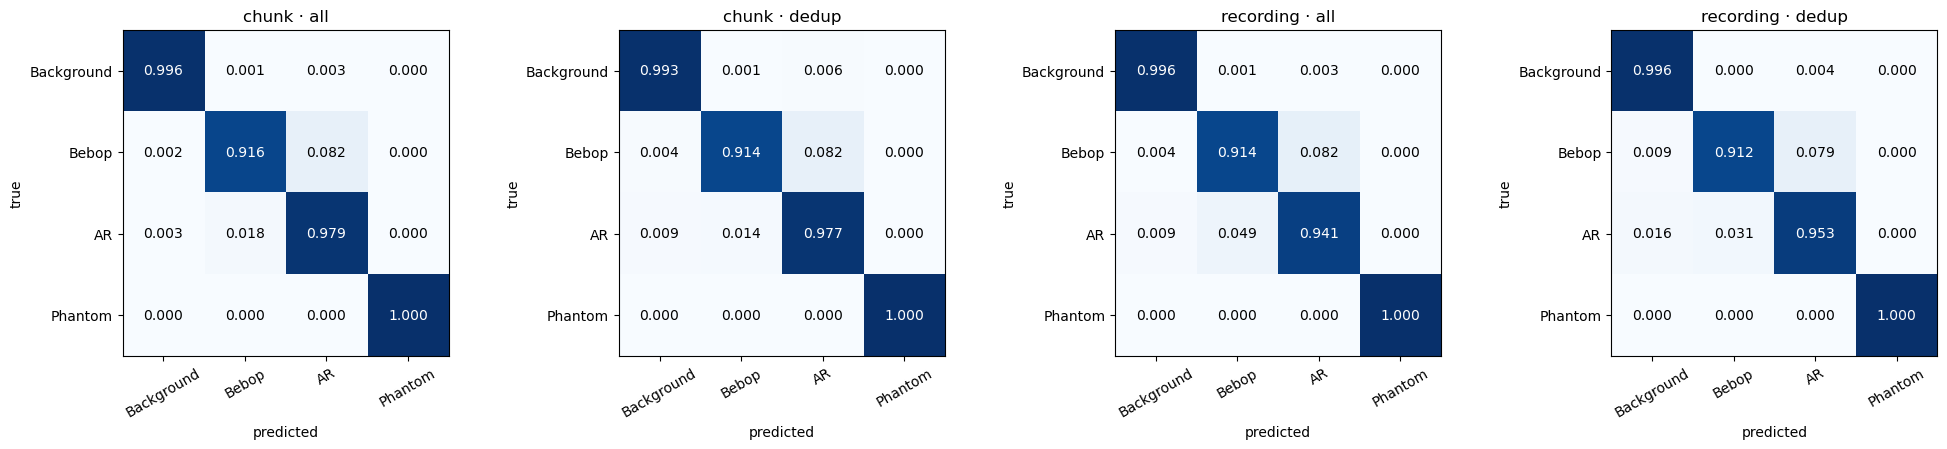

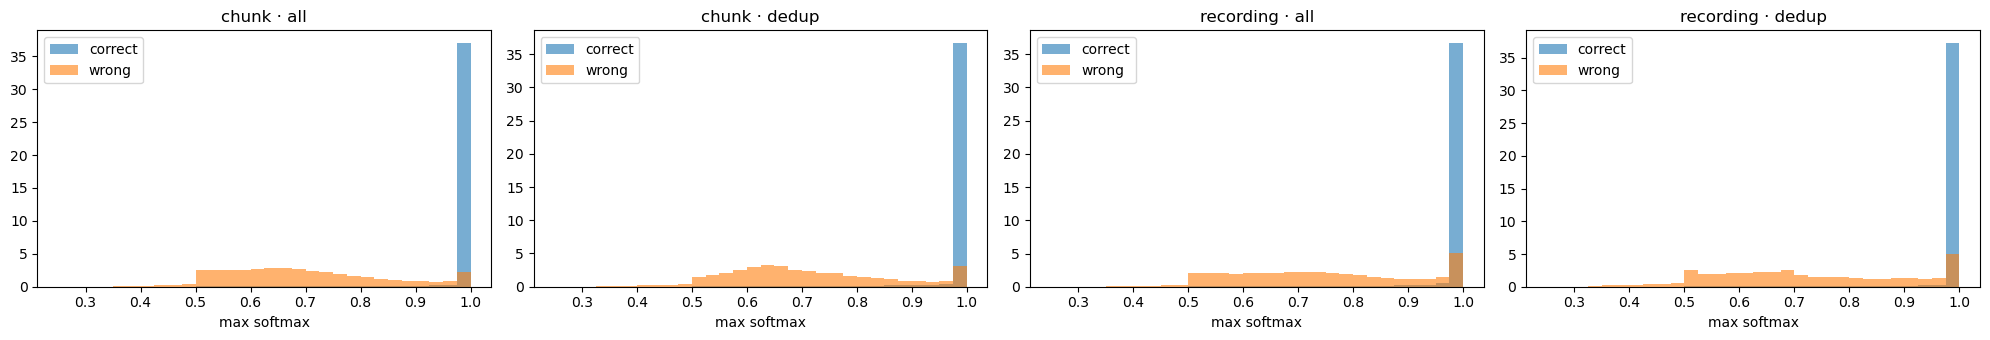

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (mode, dedup) in zip(axes, itertools.product(MODES, DEDUPS)):
    cm = sum(rep["confusion_matrix"] for k, rep in reports.items() if k[:2] == (mode, dedup))
    cm_norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i, j in itertools.product(range(N_CLASSES), repeat=2):
        ax.text(j, i, f"{cm_norm[i, j]:.3f}", ha="center", va="center", color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=30); ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
    ax.set_title(f"{mode} · {'dedup' if dedup else 'all'}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); fig.savefig(os.path.join(results_path, "confusion_matrices.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 3.5), sharey=False)
bins = np.linspace(0.25, 1, 31)
for ax, (mode, dedup) in zip(axes, itertools.product(MODES, DEDUPS)):
    sel = [rep for k, rep in reports.items() if k[:2] == (mode, dedup)]
    ax.hist(np.concatenate([r["conf_correct"] for r in sel]), bins=bins, alpha=0.6, density=True, label="correct")
    ax.hist(np.concatenate([r["conf_wrong"] for r in sel]), bins=bins, alpha=0.6, density=True, label="wrong")
    ax.set_title(f"{mode} · {'dedup' if dedup else 'all'}"); ax.set_xlabel("max softmax"); ax.legend()
plt.tight_layout(); fig.savefig(os.path.join(results_path, "confidence_histograms.png"), dpi=150, bbox_inches="tight"); plt.show()

## Source model for paper 3

Seed 0, `recording` mode, dedup on; fold chosen by **validation** macro-F1 (test metrics shown, not used).
Exported to `checkpoints/paper3/source_wpd_cnn.{pt,onnx}`; the MoMLeT-2025 model in `checkpoints/v2/` stays as is.

In [8]:
cand = runs[(runs["mode"] == "recording") & runs["dedup"] & (runs["seed"] == 0)]
best = cand.loc[cand["val_macro_f1"].idxmax()]
print(best[["fold", "val_macro_f1", "accuracy", "macro_f1"]])

import shutil
src_pt = os.path.join(DATA_PATH, "checkpoints/paper3/source_wpd_cnn.pt")
shutil.copy(os.path.join(ckpt_path, run_tag("recording", True, 0, int(best["fold"])) + ".pt"), src_pt)
print("export with: python -m rfml_uav.utils.export_onnx --ckpt", src_pt, "--onnx", src_pt.replace(".pt", ".onnx"))

fold                   1
val_macro_f1    0.981801
accuracy        0.972703
macro_f1        0.971871
Name: 76, dtype: object
export with: python -m rfml_uav.utils.export_onnx --ckpt /home/ivan/work/ml/rfml-uav/data/drone-rf/checkpoints/paper3/source_wpd_cnn.pt --onnx /home/ivan/work/ml/rfml-uav/data/drone-rf/checkpoints/paper3/source_wpd_cnn.onnx
